**Problem 1** a

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

train_dataset = datasets.MNIST(
    'mnist_data/', train=True, download=True,
    transform=transforms.ToTensor()
)

test_dataset = datasets.MNIST(
    'mnist_data/', train=False, download=True,
    transform=transforms.ToTensor()
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=64, shuffle=False
)


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view(-1, 784)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x


model = Net().to(device)
print(model)

cuda
Net(
  (fc1): Linear(in_features=784, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=50, bias=True)
  (fc3): Linear(in_features=50, out_features=50, bias=True)
  (fc4): Linear(in_features=50, out_features=10, bias=True)
)


In [22]:
def ibp_linear(lower, upper, layer):
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    new_center = F.linear(center, layer.weight, layer.bias)
    new_radius = F.linear(radius, layer.weight.abs())

    return new_center - new_radius, new_center + new_radius


def ibp_forward(model, x, eps):
    lower = torch.clamp(x.view(-1, 784) - eps, 0, 1)
    upper = torch.clamp(x.view(-1, 784) + eps, 0, 1)

    for layer in [model.fc1, model.fc2, model.fc3]:
        lower, upper = ibp_linear(lower, upper, layer)
        lower = F.relu(lower)
        upper = F.relu(upper)

    lower, upper = ibp_linear(lower, upper, model.fc4)

    return lower, upper


def ibp_margins(model, x, y, eps):
    lower = torch.clamp(x.view(-1, 784) - eps, 0, 1)
    upper = torch.clamp(x.view(-1, 784) + eps, 0, 1)

    for layer in [model.fc1, model.fc2, model.fc3]:
        lower, upper = ibp_linear(lower, upper, layer)
        lower = F.relu(lower)
        upper = F.relu(upper)

    W = model.fc4.weight
    b = model.fc4.bias
    margin_W = W[y].unsqueeze(1) - W.unsqueeze(0)
    margin_b = b[y].unsqueeze(1) - b.unsqueeze(0)
    center = (lower + upper) / 2
    radius = (upper - lower) / 2
    margin_center = torch.bmm(margin_W, center.unsqueeze(2)).squeeze(2) + margin_b
    margin_radius = torch.bmm(margin_W.abs(), radius.unsqueeze(2)).squeeze(2)

    return margin_center - margin_radius


def ibp_loss(model, x, y, eps, kappa):
    standard_loss = F.cross_entropy(model(x), y)
    margins = ibp_margins(model, x, y, eps)
    robust_loss = F.cross_entropy(-margins, y)

    return kappa * standard_loss + (1 - kappa) * robust_loss


In [23]:
def train(model, train_loader, ibp=False):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    start = time.time()

    for epoch in range(20):
        model.train()
        total_loss = 0
        kappa = 1 - 0.5 * (epoch / 19)
        eps = 0.1 * (epoch / 19)

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            if ibp:
                loss = ibp_loss(model, images, labels, eps, kappa)
            else:
                loss = F.cross_entropy(model(images), labels)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print("Epoch:", epoch + 1, "Loss:", total_loss / len(train_loader))

    return time.time() - start


In [24]:
standard_model = Net().to(device)
ibp_model = Net().to(device)
standard_time = train(standard_model, train_loader, ibp=False)
ibp_time = train(ibp_model, train_loader, ibp=True)
print("Standard training time:", standard_time)
print("IBP training time:", ibp_time)

Epoch: 1 Loss: 0.4165319687943024
Epoch: 2 Loss: 0.17630973044655787
Epoch: 3 Loss: 0.13349380751432322
Epoch: 4 Loss: 0.10670159092254397
Epoch: 5 Loss: 0.0892090353328409
Epoch: 6 Loss: 0.07760855341965614
Epoch: 7 Loss: 0.0691163625487728
Epoch: 8 Loss: 0.05816712088710162
Epoch: 9 Loss: 0.05093803813049037
Epoch: 10 Loss: 0.0459812200607867
Epoch: 11 Loss: 0.042175232112206126
Epoch: 12 Loss: 0.03766928721831909
Epoch: 13 Loss: 0.032886080400948016
Epoch: 14 Loss: 0.030599381425107684
Epoch: 15 Loss: 0.02659843844039041
Epoch: 16 Loss: 0.02632498669887405
Epoch: 17 Loss: 0.024644748550671367
Epoch: 18 Loss: 0.02181701433006128
Epoch: 19 Loss: 0.0194844399455659
Epoch: 20 Loss: 0.01992065191705106
Epoch: 1 Loss: 0.4458721845722529
Epoch: 2 Loss: 0.23656171735431722
Epoch: 3 Loss: 0.22125622428365863
Epoch: 4 Loss: 0.2062742402975652
Epoch: 5 Loss: 0.20074438008624734
Epoch: 6 Loss: 0.2011338014131797
Epoch: 7 Loss: 0.20642385235441518
Epoch: 8 Loss: 0.21855873142732485
Epoch: 9 Loss

In [25]:
def test_accuracy(model, test_loader):
    model.eval()
    correct = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()

    return correct / len(test_loader.dataset)


print("Standard model accuracy:", test_accuracy(standard_model, test_loader))
print("IBP model accuracy:", test_accuracy(ibp_model, test_loader))

Standard model accuracy: 0.9733
IBP model accuracy: 0.9554


In [26]:
def pgd_attack(model, x, y, eps, steps=20):
    model.eval()
    alpha = eps / 4
    x_adv = x.clone().detach()

    for _ in range(steps):
        x_adv.requires_grad_(True)

        outputs = model(x_adv)
        loss = F.cross_entropy(outputs, y)
        grad = torch.autograd.grad(loss, x_adv)[0]

        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.max(torch.min(x_adv, x + eps), x - eps)
        x_adv = torch.clamp(x_adv, 0, 1)

    return x_adv.detach()

In [27]:
def pgd_accuracy(model, test_loader, eps=0.1):
    model.eval()
    correct = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        x_adv = pgd_attack(model, images, labels, eps)

        with torch.no_grad():
            predictions = model(x_adv).argmax(dim=1)
            correct += (predictions == labels).sum().item()

    return correct / len(test_loader.dataset)

standard_pgd_acc = pgd_accuracy(standard_model, test_loader, eps=0.1)
ibp_pgd_acc = pgd_accuracy(ibp_model, test_loader, eps=0.1)

print("Standard model PGD accuracy:", standard_pgd_acc)
print("IBP model PGD accuracy:", ibp_pgd_acc)

Standard model PGD accuracy: 0.0142
IBP model PGD accuracy: 0.8345


**Problem 1** b

In [28]:
def certify(model, images, labels, eps):
    margins = ibp_margins(model, images, labels, eps)
    mask = F.one_hot(labels, num_classes=10).bool()

    return ((margins > 0) | mask).all(dim=1)


def verified_accuracy(model, test_loader, eps):
    model.eval()
    certified = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            verified = certify(model, images, labels, eps)
            certified += verified.sum().item()

    return certified / len(test_loader.dataset)

Epsilon: 0.01, Verified accuracy: 94.58%
Epsilon: 0.02, Verified accuracy: 93.32%
Epsilon: 0.03, Verified accuracy: 92.09%
Epsilon: 0.04, Verified accuracy: 90.73%
Epsilon: 0.05, Verified accuracy: 89.35%
Epsilon: 0.06, Verified accuracy: 87.68%
Epsilon: 0.07, Verified accuracy: 85.74%
Epsilon: 0.08, Verified accuracy: 83.19%
Epsilon: 0.09, Verified accuracy: 80.43%
Epsilon: 0.10, Verified accuracy: 77.39%


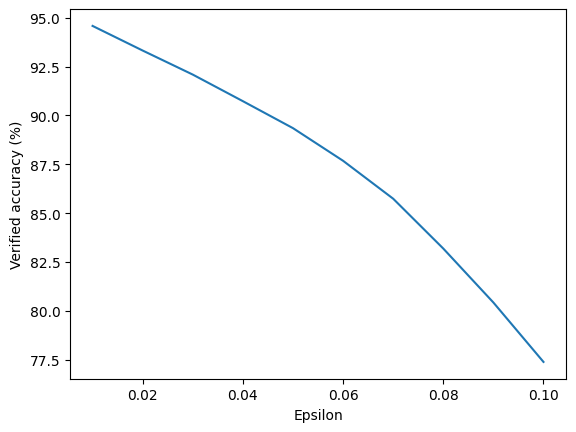

In [29]:
eps_values = np.arange(0.01, 0.101, 0.01)
accuracies = []

for eps in eps_values:
    acc = verified_accuracy(ibp_model, test_loader, eps)
    accuracies.append(acc * 100)
    print(f"Epsilon: {eps:.2f}, Verified accuracy: {acc * 100:.2f}%")

plt.plot(eps_values, accuracies)
plt.xlabel("Epsilon")
plt.ylabel("Verified accuracy (%)")
plt.show()

In [30]:
examples = []

for eps in [0.03, 0.06, 0.1]:
    found = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.no_grad():
            verified = certify(ibp_model, images, labels, eps)
            predictions = ibp_model(images).argmax(dim=1)

        selected = (verified == False) & (predictions == labels)

        x = images[selected]
        y = labels[selected]

        if len(y) == 0:
            continue

        x_adv = pgd_attack(ibp_model, x, y, eps)

        with torch.no_grad():
            adv_predictions = ibp_model(x_adv).argmax(dim=1)

        for i in range(len(y)):
            if adv_predictions[i] != y[i]:
                examples.append((x[i], x_adv[i], y[i].item(), adv_predictions[i].item(), eps))
                found += 1

                if found >= 2:
                    break

        if found >= 2:
            break

    print("Epsilon:", eps, "Examples found:", found)

Epsilon: 0.03 Examples found: 2
Epsilon: 0.06 Examples found: 2
Epsilon: 0.1 Examples found: 2


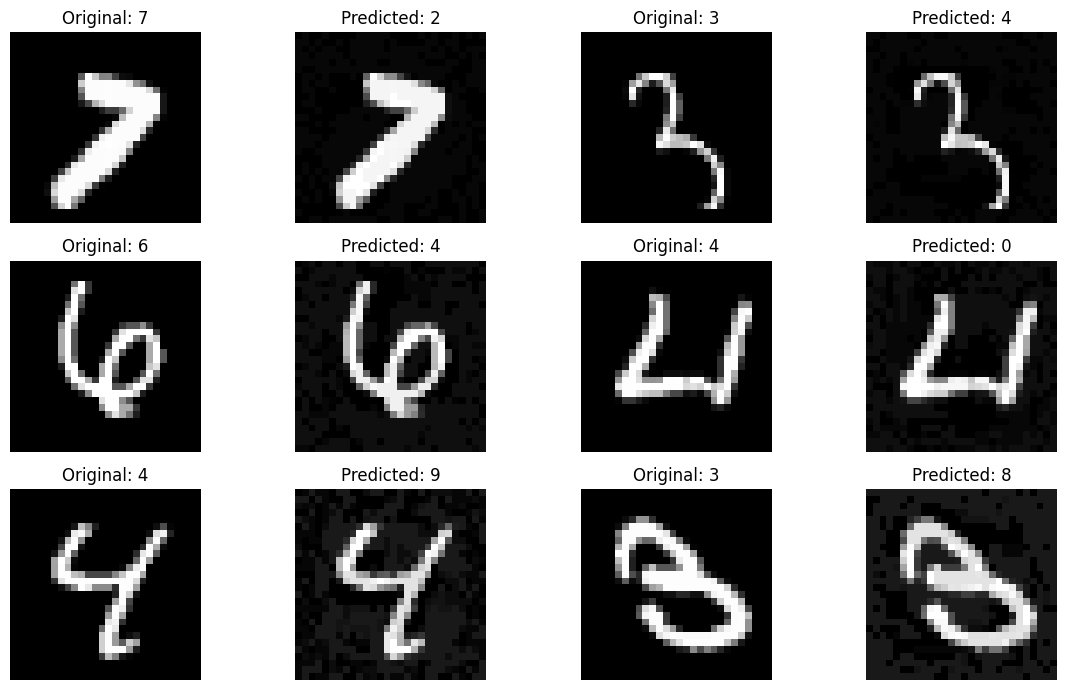

In [31]:
plt.figure(figsize=(12, 7))
for i in range(len(examples)):
    original, attacked, label, prediction, eps = examples[i]
    plt.subplot(3, 4, 2 * i + 1)
    plt.imshow(original[0].detach().cpu(), cmap="gray")
    plt.title("Original: " + str(label))
    plt.axis("off")
    plt.subplot(3, 4, 2 * i + 2)
    plt.imshow(attacked[0].detach().cpu(), cmap="gray")
    plt.title("Predicted: " + str(prediction))
    plt.axis("off")
plt.tight_layout()
plt.savefig("adversarial_examples.png")
plt.show()